Connexion à PostgreSQL réussie pour la visualisation !
Génération du graphique 1 : Distribution des sentiments...


/tmp/ipykernel_10029/649969295.py:34: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sentiment = pd.read_sql(query_sentiment, conn)


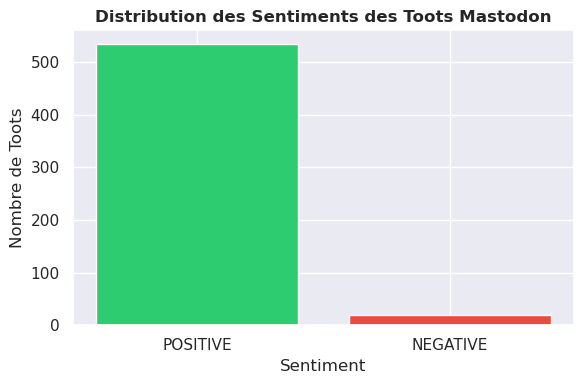

Génération du graphique 2 : Fréquence des toots dans le temps...


/tmp/ipykernel_10029/649969295.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_time = pd.read_sql(query_time, conn)


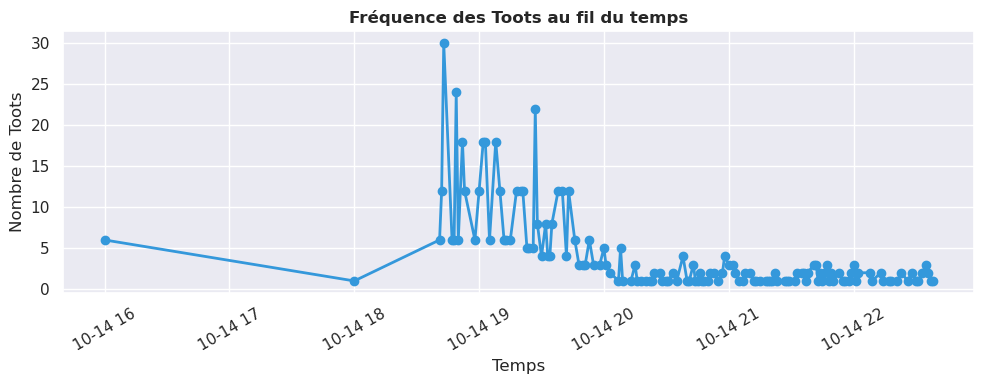

Génération du graphique 3 : Top des Hashtags...


/tmp/ipykernel_10029/649969295.py:74: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_text = pd.read_sql(query_text, conn)


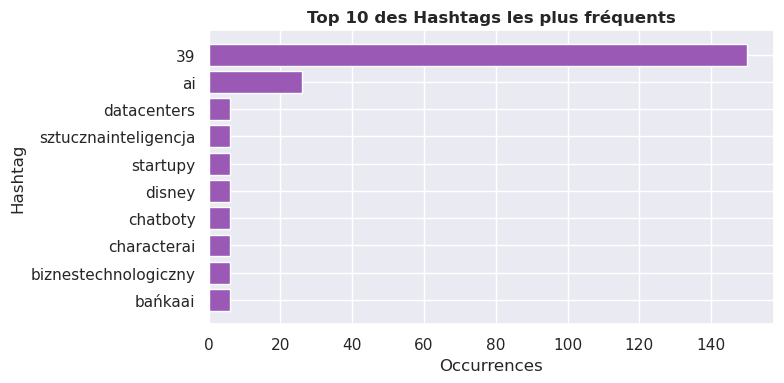

Génération du graphique 4 : Activité des utilisateurs (Heatmap)...


/tmp/ipykernel_10029/649969295.py:100: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_user = pd.read_sql(query_user_activity, conn)


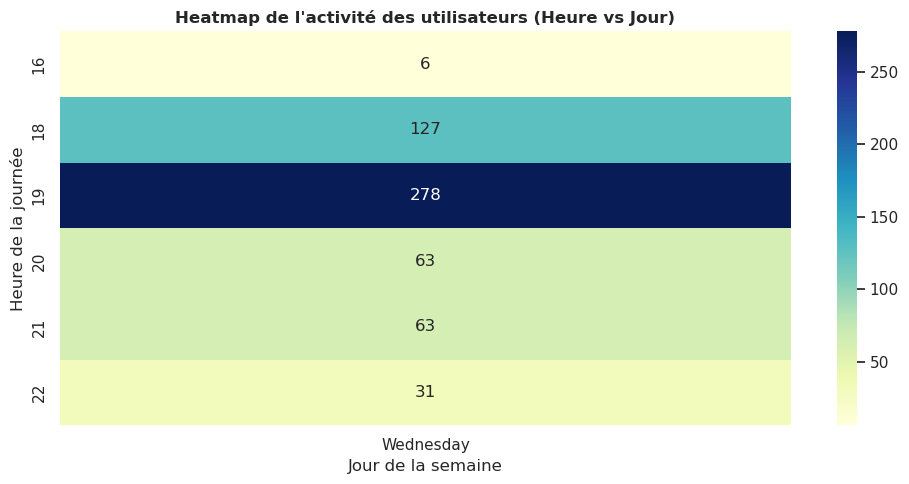

Visualisation terminée avec succès !


In [ ]:
# Installation des bibliothèques nécessaires 
!pip install -q psycopg2-binary matplotlib seaborn pandas

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as seaborn_plt
import psycopg2
import re

# Configuration du style des graphiques pour Jupyter
%matplotlib inline
seaborn_plt.set_theme(style="darkgrid")
plt.rcParams.update({'figure.autolayout': True})

# 2. Connexion à PostgreSQL 
    conn = psycopg2.connect(
        dbname="mastodon_db",
        user="postgres",
        password="postgres",
        host="postgres",
        port="5432"
    )
    print("Connexion à PostgreSQL réussie pour la visualisation !")
except Exception as e:
    print(f"Erreur de connexion à PostgreSQL : {e}")
    exit(1)

# ==========================================
# GRAPHIQUE 1 : Sentiment Distribution (Bar Chart)
# ==========================================
print("Génération du graphique 1 : Distribution des sentiments...")
query_sentiment = "SELECT sentiment_label, COUNT(*) as count FROM toots_sentiment GROUP BY sentiment_label;"
df_sentiment = pd.read_sql(query_sentiment, conn)

if not df_sentiment.empty:
    plt.figure(figsize=(6, 4))
    plt.bar(df_sentiment['sentiment_label'], df_sentiment['count'], color=['#2ecc71', '#e74c3c'])
    plt.title('Distribution des Sentiments des Toots Mastodon', fontsize=12, fontweight='bold')
    plt.xlabel('Sentiment')
    plt.ylabel('Nombre de Toots')
    plt.show()
else:
    print("Aucune donnée de sentiment trouvée.")

# ==========================================
# GRAPHIQUE 2 : Toot Frequency Over Time (Line Chart)
# ==========================================
print("Génération du graphique 2 : Fréquence des toots dans le temps...")
query_time = "SELECT timestamp FROM toots_filtered WHERE timestamp IS NOT NULL;"
df_time = pd.read_sql(query_time, conn)

if not df_time.empty:
    # Utilisation de format='ISO8601' pour supporter les fuseaux horaires (+00:00)
    df_time['timestamp'] = pd.to_datetime(df_time['timestamp'], format='ISO8601')
    df_time['time_slot'] = df_time['timestamp'].dt.floor('min')
    df_time_grouped = df_time.groupby('time_slot').size().reset_index(name='toot_count')

    plt.figure(figsize=(10, 4))
    plt.plot(df_time_grouped['time_slot'], df_time_grouped['toot_count'], marker='o', color='#3498db', linewidth=2)
    plt.title('Fréquence des Toots au fil du temps', fontsize=12, fontweight='bold')
    plt.xlabel('Temps')
    plt.ylabel('Nombre de Toots')
    plt.xticks(rotation=30)
    plt.show()
else:
    print("Aucun timestamp trouvé.")

# ==========================================
# GRAPHIQUE 3 : Top Hashtags (Horizontal Bar Chart)
# ==========================================
print("Génération du graphique 3 : Top des Hashtags...")
query_text = "SELECT text FROM toots_filtered;"
df_text = pd.read_sql(query_text, conn)

if not df_text.empty:
    hashtags = []
    for text in df_text['text'].dropna():
        found = re.findall(r"#(\w+)", text)
        hashtags.extend([h.lower() for h in found])

    if hashtags:
        df_hash = pd.Series(hashtags).value_counts().head(10).reset_index()
        df_hash.columns = ['hashtag', 'count']

        plt.figure(figsize=(8, 4))
        plt.barh(df_hash['hashtag'][::-1], df_hash['count'][::-1], color='#9b59b6')
        plt.title('Top 10 des Hashtags les plus fréquents', fontsize=12, fontweight='bold')
        plt.xlabel('Occurrences')
        plt.ylabel('Hashtag')
        plt.show()
    else:
        print("Aucun hashtag trouvé dans les toots.")

# ==========================================
# GRAPHIQUE 4 : User Activity (Heatmap)
# ==========================================
print("Génération du graphique 4 : Activité des utilisateurs (Heatmap)...")
query_user_activity = "SELECT user_id, timestamp FROM toots_filtered WHERE timestamp IS NOT NULL AND user_id IS NOT NULL;"
df_user = pd.read_sql(query_user_activity, conn)

if not df_user.empty:
    df_user['timestamp'] = pd.to_datetime(df_user['timestamp'], format='ISO8601')
    df_user['hour'] = df_user['timestamp'].dt.hour
    df_user['day_of_week'] = df_user['timestamp'].dt.day_name()

    pivot_table = df_user.pivot_table(index='hour', columns='day_of_week', aggfunc='size', fill_value=0)

    if not pivot_table.empty:
        plt.figure(figsize=(10, 5))
        seaborn_plt.heatmap(pivot_table, cmap="YlGnBu", annot=True, fmt="d", cbar=True)
        plt.title('Heatmap de l\'activité des utilisateurs (Heure vs Jour)', fontsize=12, fontweight='bold')
        plt.xlabel('Jour de la semaine')
        plt.ylabel('Heure de la journée')
        plt.show()
    else:
        print("Pas assez de données pour générer la heatmap.")

# Fermeture de la connexion
conn.close()
print("Visualisation terminée avec succès !")